# NeedlePoint
### Find the needle on day one.

*Which new vulnerabilities will actually get attacked?*

**DSCI 510 · project demo** · Saswata Mukherjee · November 2026

This notebook walks through the project from start to finish: the problem, collecting data from three public APIs,
turning nested JSON into one pandas table, the analysis behind four questions, and **NeedlePoint**, a ranking model
chosen in a fair competition and measured against the industry benchmark. The complete download (about 200,000 CVE records plus a year of daily EPSS
scores, about half an hour of API calls) was run beforehand and saved under `data/`. Here the same code runs on a small scale, and every result below is computed in
this notebook from the saved data.

1. The problem
2. Collecting the data from three APIs
3. From a nested record to a clean row
4. One table for everything
5. What the data shows (Q1, Q3)
6. Ranking new CVEs (Q2)
7. Against EPSS (Q4)
8. Conclusion

In [1]:
import gzip
import json
import os
import re
import textwrap
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import scipy.sparse as sp
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder, StandardScaler

ROOT = Path.cwd().parent if Path.cwd().name == "Demo" else Path.cwd()   # the project folder
DATA = ROOT / "data"

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 130)

## 1. The problem

Every publicly known software flaw gets an ID, a **CVE**. Tens of thousands are published every year (39,953 in
2024, about 110 a day), and only a small share are ever used by attackers. The best public record of which ones
were is CISA's **Known Exploited Vulnerabilities (KEV)** catalogue.

No security team can patch everything at once, so each new CVE raises the same question on the day it appears: fix it
now, or later? **Panel A** shows why this is hard. The decision has to be made on publication day, using only what
the CVE's publisher released that day. Whether attackers will actually use the flaw becomes clear days or months
later, when (and if) CISA lists it in KEV. Anything that only arrives after day 0 cannot be used to make the
decision; a ranking that used it would be looking at the answer.

**Panel B** shows the scale. The usual shortcut is the CVSS severity score: fix everything rated 7.0 or higher. The
cell below the figure computes what that rule achieved in 2024 (the table it reads is built in section 4).

![problem](figures/problem.png)

In [2]:
table = pd.read_parquet(DATA / "processed" / "analysis_table.parquet")    # built in section 4
cves_2024 = table[table["split"] == "test"]

n, exploited = len(cves_2024), int(cves_2024["label_365"].sum())
flagged = cves_2024["cvss_score"] >= 7
caught = int(cves_2024.loc[flagged, "label_365"].sum())

print(f"CVEs published in 2024:          {n:,}")
print(f"listed in KEV within a year:     {exploited}  ({exploited / n:.2%}, 1 in {n // exploited})")
print(f"rule 'fix everything CVSS 7.0+': {flagged.mean():.0%} of all CVEs to fix")
print(f"   ... and it catches:           {caught} of {exploited} exploited "
      f"({caught / exploited:.0%})")

CVEs published in 2024:          39,953
listed in KEV within a year:     149  (0.37%, 1 in 268)
rule 'fix everything CVSS 7.0+': 32% of all CVEs to fix
   ... and it catches:           92 of 149 exploited (62%)


The rule asks a team to fix a third of everything and still misses close to 40% of what attackers used. A better
approach is a **ranked list**: for the same amount of work, or less, it should catch more of the CVEs that will be
exploited. Section 6 turns "catch more for the same work" into a number.

**The central question:** on the day a CVE is published, using only what is known that day, can CVEs be put in an
order where the few that will be exploited come near the top? Four questions frame the project:

| | Question |
|:--|:--|
| Q1 | Which publication-day traits (severity, weakness type, publisher) go with exploitation? |
| Q2 | Can those traits rank new CVEs better than severity alone? |
| Q3 | How long after publication are exploited CVEs listed in KEV? |
| Q4 | How does the ranking compare with EPSS, the industry's public exploit-prediction score? |

![pipeline](figures/pipeline.png)

## 2. Collecting the data from three APIs

| Source | What the project takes from it | Access | Accessed |
|:--|:--|:--|:--|
| [NVD CVE API 2.0](https://nvd.nist.gov/developers/vulnerabilities) (NIST) | every CVE published 2016–2024: description, publisher, severity, weakness type | free API key; 50 requests per 30 s (5 without a key); at most 2,000 records per page and 120 days per query | Nov 10, 2026 (full download); again live in this notebook |
| [CISA KEV catalogue](https://www.cisa.gov/known-exploited-vulnerabilities-catalog) | which CVEs were exploited, and the date each was listed (the label) | one JSON file, no key | Nov 10, 2026 (catalogue version 2026.11.10); again live in this notebook |
| [EPSS API](https://www.first.org/epss/api) (FIRST) | the EPSS score of each 2024 CVE 1, 7 and 30 days after publication (the benchmark) | no key | Nov 10, 2026 (daily score files for Jan 2, 2024 – Jan 31, 2025); the API again live in this notebook |

The full NVD download needed 28 date windows (at most 120 days each) and 117 pages of up to 2,000 records,
paced 6 seconds apart as NIST asks bulk users to do. The building blocks are
below: the API key is read from a local `.env` file and never displayed, a small `get_json` helper retries when the
server is busy, and a **generator** walks through the pages of one query, yielding one CVE at a time.
After a one-day example, the 120-day windows and the full download's own completeness record are shown.

In [3]:
NVD_URL = "https://services.nvd.nist.gov/rest/json/cves/2.0"
KEV_URL = "https://www.cisa.gov/sites/default/files/feeds/known_exploited_vulnerabilities.json"
EPSS_URL = "https://api.first.org/data/v1/epss"
AGENT = {"User-Agent": "DSCI510-course-project/1.0 (academic research)"}
MAX_WINDOW_DAYS = 120                     # the NVD answers at most 120 days per query


def load_api_key(var="NVD_API_KEY", env_file=ROOT / ".env"):
    "The NVD API key from the environment or the .env file, or None. Never printed."
    if os.environ.get(var):
        return os.environ[var].strip()
    if env_file.exists():
        for line in env_file.read_text(encoding="utf-8").splitlines():
            name, sep, value = line.strip().partition("=")
            value = value.strip().strip('"').strip("'")
            if sep and name.strip() == var and value and "your-key" not in value:
                return value
    return None


api_key = load_api_key()
# the key goes only to the NVD, inside a request header
NVD_HEADERS = {**AGENT, "apiKey": api_key} if api_key else AGENT
print("NVD API key found:", api_key is not None)


class ApiError(RuntimeError):
    "A request that failed for a known reason (unreachable, refused, not JSON)."


def get_json(url, params=None, headers=AGENT, attempts=3, timeout=15):
    "GET a URL and return the parsed JSON; wait and retry when the server is busy."
    host = url.split("/")[2]
    for attempt in range(1, attempts + 1):
        try:
            resp = requests.get(url, params=params, headers=headers, timeout=timeout)
        except requests.RequestException as exc:
            raise ApiError(f"could not reach {host} ({type(exc).__name__})") from exc
        if resp.status_code == 200:
            try:
                return resp.json()
            except ValueError as exc:
                raise ApiError("the answer was not JSON") from exc
        if resp.status_code in (403, 429, 500, 502, 503, 504) and attempt < attempts:
            time.sleep(6 * attempt)           # the NVD answers 403 when asked too fast
            continue
        # the NVD gives its reason in a "message" header with an empty body; other servers use the body
        reason = resp.headers.get("message") or resp.text[:120].strip()
        raise ApiError(f"HTTP {resp.status_code} from {host}" + (f": {reason}" if reason else ""))


def iter_cves(start, end, page_size=50):
    "Yield every CVE the NVD lists as published in [start, end), one page at a time."
    span = pd.Timestamp(end[:19]) - pd.Timestamp(start[:19])     # [:19] drops the ".000Z"
    if span > pd.Timedelta(MAX_WINDOW_DAYS, unit="D"):
        raise ValueError(f"the NVD answers at most {MAX_WINDOW_DAYS} days per query, not {span.days}: "
                         "split the range with windows_between()")
    index, total = 0, None
    while total is None or index < total:
        params = {"pubStartDate": start, "pubEndDate": end,
                  "resultsPerPage": page_size, "startIndex": index}
        page = get_json(NVD_URL, params, headers=NVD_HEADERS)
        try:
            total, batch = page["totalResults"], page["vulnerabilities"]
        except (KeyError, TypeError) as exc:
            raise ApiError("the NVD's answer had an unexpected shape") from exc
        first, last = index + 1, index + len(batch)
        print(f"  page {index // page_size + 1}: records {first}-{last} of {total}")
        if not batch:
            break
        yield from (item["cve"] for item in batch)
        index += len(batch)
        if index < total:
            time.sleep(1 if api_key else 6)   # stay under NIST's rate limit

NVD API key found: True


A real query: every CVE published on one day, **April 12, 2024** (`DAY`), 50 per page. If the network or the NVD is
unavailable, the cell falls back to the records the full download saved on November 10, 2026, taken from the saved
window file that contains that day, so the demo never depends on the Wi-Fi.

In [4]:
RAW_NVD = DATA / "raw" / "nvd"
DAY = "2024-04-12"                        # the rest of the demo follows CVE-2024-3400, published this day


def saved_cves(day):
    "One day's records ('YYYY-MM-DD'), from the window file the full download saved for that day."
    for path in sorted(RAW_NVD.glob("*.jsonl.gz")):
        first, last = path.name[:10], path.name[11:21]        # e.g. '2024-02-23_2024-06-21.jsonl.gz'
        if first <= day < last:                               # a window holds its first day, not its last
            with gzip.open(path, "rt", encoding="utf-8") as fh:
                return [cve for cve in map(json.loads, fh) if cve["published"].startswith(day)]
    raise ValueError(f"no saved window covers {day}: the download spans 2016-01-01 to 2024-12-31")


next_day = (pd.Timestamp(DAY) + pd.Timedelta(1, unit="D")).strftime("%Y-%m-%d")
try:
    day = list(iter_cves(f"{DAY}T00:00:00.000Z", f"{next_day}T00:00:00.000Z"))
    source = "live from the NVD API"
except ApiError as exc:
    print(f"NVD request failed ({exc}): using the saved copy instead")
    day, source = saved_cves(DAY), "from the saved copy"

print(f"\n{len(day)} records published on {DAY}, {source}")
record = next(cve for cve in day if cve["id"] == "CVE-2024-3400")
print(f"one of them, {record['id']}, is a {type(record).__name__} with {len(record)} keys:")
print(textwrap.fill(", ".join(record), width=90, initial_indent="  ", subsequent_indent="  "))


  page 1: records 1-50 of 129
  page 2: records 51-100 of 129
  page 3: records 101-129 of 129

129 records published on 2024-04-12, live from the NVD API
one of them, CVE-2024-3400, is a dict with 16 keys:
  id, sourceIdentifier, published, lastModified, vulnStatus, cveTags, descriptions,
  affected, metrics, cisaExploitAdd, cisaActionDue, cisaRequiredAction,
  cisaVulnerabilityName, weaknesses, configurations, references


### Scaling up: nine years in 120-day windows

One day fits in one query. Nine years do not: the NVD answers **at most 120 days per query**, and it says so in an
unusual way, with HTTP 404, an empty body and the reason in a header named `message`. `get_json` now reports that
header, and `iter_cves` refuses a longer range itself, before sending anything. The first cell shows both.

In [5]:
# What the NVD answers to a 366-day query (2024 is a leap year)
one_year = {"pubStartDate": "2024-01-01T00:00:00.000Z", "pubEndDate": "2024-12-31T23:59:59.999Z",
            "resultsPerPage": 1}
try:
    get_json(NVD_URL, one_year, headers=NVD_HEADERS, attempts=1)
    print("unexpected: the NVD accepted a whole year")
except ApiError as exc:
    if "120" in str(exc):
        print("live answer:", exc)
    else:                                     # NVD unreachable: show what the validation run recorded
        report = json.loads((ROOT / "logs" / "validation_report.json").read_text(encoding="utf-8"))
        step = report["steps"]["08-date-limit-understood"]
        print(f"NVD not reachable ({exc})")
        print(f"recorded when the sources were validated: HTTP {step['status']} from "
              f"services.nvd.nist.gov: {step['message']}")

# iter_cves stops a range that is too long before any request is sent
try:
    next(iter_cves("2016-01-01T00:00:00.000Z", "2025-01-01T00:00:00.000Z"))
except ValueError as exc:
    print("iter_cves:", exc)


live answer: HTTP 404 from services.nvd.nist.gov: Date range cannot exceed 120 days.
iter_cves: the NVD answers at most 120 days per query, not 3288: split the range with windows_between()


So the full download cut 2016–2024 into windows with `windows_between` below: each window starts where the previous
one ended, so no CVE can fall in a gap or be fetched twice. `check_windows` confirms this on the real windows, and a
deliberately bad list (windows 400 days wide) shows that it does catch a problem. Each window was then fetched page
by page, at 2,000 records per page and 6 seconds apart.

In [6]:
FMT = "%Y-%m-%dT%H:%M:%S.000Z"            # the NVD's timestamp format
SPAN = ("2016-01-01", "2025-01-01")       # every CVE published 2016-2024


def windows_between(start, stop, max_days=MAX_WINDOW_DAYS):
    "Yield (start, end) pairs covering [start, stop), each at most max_days - 1 days wide."
    step, cursor, stop = pd.Timedelta(max_days - 1, unit="D"), pd.Timestamp(start), pd.Timestamp(stop)
    while cursor < stop:
        end = min(cursor + step, stop)
        yield cursor.strftime(FMT), end.strftime(FMT)
        cursor = end                          # the next window starts exactly where this one ended


def check_windows(pairs, start, stop, max_days=MAX_WINDOW_DAYS):
    "The problems with a list of windows: too wide, a gap or overlap, or the wrong ends."
    parse = lambda s: pd.Timestamp(s[:19])
    problems = []
    if max(parse(b) - parse(a) for a, b in pairs) > pd.Timedelta(max_days, unit="D"):
        problems.append(f"a window is wider than {max_days} days")
    if any(pairs[i][0] != pairs[i - 1][1] for i in range(1, len(pairs))):
        problems.append("a gap or overlap between windows")
    if parse(pairs[0][0]) != pd.Timestamp(start) or parse(pairs[-1][1]) != pd.Timestamp(stop):
        problems.append("the windows don't start and end on the requested dates")
    return problems


WINDOWS = list(windows_between(*SPAN))
print(f"{len(WINDOWS)} windows from {SPAN[0]} to {SPAN[1]}:")
for number in (0, 1, len(WINDOWS) - 1):
    start, end = WINDOWS[number]
    print(f"  {number + 1:>2}: {start} -> {end}")

# Checks: the windows pass, and the check does catch a bad list (windows 400 days wide)
assert check_windows(WINDOWS, *SPAN) == []
assert check_windows(list(windows_between(*SPAN, max_days=400)), *SPAN) != []
print("no window too wide, no gaps, no overlaps")


28 windows from 2016-01-01 to 2025-01-01:
   1: 2016-01-01T00:00:00.000Z -> 2016-04-29T00:00:00.000Z
   2: 2016-04-29T00:00:00.000Z -> 2016-08-26T00:00:00.000Z
  28: 2024-10-18T00:00:00.000Z -> 2025-01-01T00:00:00.000Z
no window too wide, no gaps, no overlaps


**The same method on a small scale.** Below, `windows_between` cuts five days (April 10–14, 2024) into 2-day
windows, and each window is fetched with its own query at the full download's page size of 2,000, as the full run
fetched its 28 windows. Each page line shows the NVD's own total next to the records received. Two checks follow:
no CVE fetched twice, and every record inside the window that fetched it.

In [7]:
MINI_SPAN = ("2024-04-10", "2024-04-15")                        # five days around DAY
mini_windows = list(windows_between(*MINI_SPAN, max_days=3))     # 2-day windows: several, in seconds
mini_days = pd.date_range(*MINI_SPAN, inclusive="left").strftime("%Y-%m-%d")
saved_by_day = {d: saved_cves(d) for d in mini_days}             # for the offline fallback

fetched = {}                                                     # (start, end) -> that window's records
for number, (start, end) in enumerate(mini_windows, 1):
    print(f"window {number} of {len(mini_windows)}: {start[:10]} -> {end[:10]}")
    try:
        fetched[(start, end)] = list(iter_cves(start, end, page_size=2000))
    except ApiError as exc:                                      # offline: the same window, saved copy
        print(f"  NVD request failed ({exc}): using the saved copy")
        fetched[(start, end)] = [cve for d in mini_days if start[:10] <= d < end[:10]
                                 for cve in saved_by_day[d]]
    if number < len(mini_windows):
        time.sleep(1 if api_key else 6)                          # pause between windows too

combined = [cve for records in fetched.values() for cve in records]
ids = [cve["id"] for cve in combined]
print(f"\n{len(combined)} records from {len(mini_windows)} windows, combined")

# Checks: no CVE twice, and every record inside its own window
assert len(ids) == len(set(ids))
for (start, end), records in fetched.items():
    assert all(start[:19] <= cve["published"][:19] < end[:19] for cve in records)
print("no duplicates, every record inside its window")


window 1 of 3: 2024-04-10 -> 2024-04-12
  page 1: records 1-368 of 368
window 2 of 3: 2024-04-12 -> 2024-04-14
  page 1: records 1-145 of 145
window 3 of 3: 2024-04-14 -> 2024-04-15
  page 1: records 1-7 of 7

520 records from 3 windows, combined
no duplicates, every record inside its window


**Did every window arrive complete?** During the full download, the records received for each window were counted
against the NVD's own total (`totalResults`), and the result was saved in `data/raw/nvd/_manifest.json` next to the
window's files. The manifest also let an interrupted download resume where it stopped. Reading it shows the whole
download without repeating it.

In [8]:
manifest = json.loads((RAW_NVD / "_manifest.json").read_text(encoding="utf-8"))
log = pd.DataFrame.from_dict(manifest, orient="index").sort_index()
pages = -(-log["expected"] // 2000)            # pages of up to 2,000 records (division rounded up)

print(f"{len(log)} windows | the NVD reported {log['expected'].sum():,} records, "
      f"{log['received'].sum():,} received | {pages.sum()} pages of up to 2,000")
withdrawn = log["rejected"].sum()
print(f"{withdrawn:,} of them are withdrawn IDs, leaving {log['rows'].sum() - withdrawn:,} CVEs")
log.iloc[[0, 1, -1]][["expected", "received", "rejected", "saved"]]


28 windows | the NVD reported 200,978 records, 200,978 received | 117 pages of up to 2,000
13,759 of them are withdrawn IDs, leaving 187,219 CVEs


,expected,received,rejected,saved
2016-01-01_2016-04-29,2038,2038,25,2026-11-10T13:59:14-08:00
2016-04-29_2016-08-26,2237,2237,17,2026-11-10T13:59:33-08:00
2024-10-18_2025-01-01,9237,9237,62,2026-11-10T14:18:51-08:00


CVE-2024-3400 is a flaw in Palo Alto Networks firewalls that was already under attack when it was published. Its record is nested JSON:
lists inside dictionaries inside lists. Below is the part that holds the scores. The `source` of each entry matters:
it can be the CVE's publisher, NVD's own analysts, or CISA.

In [9]:
for kind, entries in record["metrics"].items():
    for m in entries:
        if "cvssData" in m:
            print(f"{kind:<14} CVSS {m['cvssData']['baseScore']:>4}   from {m['source']}")
        else:                                       # CISA's SSVC block: not a CVSS score
            first_option = m.get("ssvcData", {}).get("options", [None])[0]
            print(f"{kind:<14} {first_option}   from {m['source']} (CISA)")
print("published by:", record["sourceIdentifier"])
print("KEV listing date stored in the NVD record:", record.get("cisaExploitAdd"))

cvssMetricV31  CVSS 10.0   from psirt@paloaltonetworks.com
cvssMetricV31  CVSS 10.0   from nvd@nist.gov
ssvcV203       {'exploitation': 'active'}   from 134c704f-9b21-4f2e-91b3-4a467353bcc0 (CISA)
published by: psirt@paloaltonetworks.com
KEV listing date stored in the NVD record: 2024-04-12


The other two sources, for the same CVE. KEV is a single JSON file, turned into a dictionary from CVE ID to the date
it was listed. EPSS has a `date` parameter, so the request asks for the score as it stood the day after publication,
which is what a team would have seen then (today's score already knows the answer).

In [10]:
try:
    kev = get_json(KEV_URL)
    listed_on = {entry["cveID"]: entry["dateAdded"] for entry in kev["vulnerabilities"]}
    kev_source = "live"
except (ApiError, KeyError, TypeError) as exc:
    print(f"KEV not available ({exc}): using the saved snapshot")
    kev = json.loads((DATA / "raw" / "kev" / "kev_2026.11.10.json").read_text(encoding="utf-8"))
    listed_on = {entry["cveID"]: entry["dateAdded"] for entry in kev["vulnerabilities"]}
    kev_source = "saved snapshot"

try:
    hit = get_json(EPSS_URL, {"cve": "CVE-2024-3400", "date": "2024-04-13"})["data"][0]
    epss_day1, epss_source = float(hit["epss"]), "live"
except (ApiError, KeyError, IndexError, TypeError, ValueError) as exc:
    print(f"EPSS not available ({exc}): using the saved daily file")
    path = DATA / "raw" / "epss_daily" / "epss_2024-04-13.parquet"
    saved = pd.read_parquet(path).set_index("cve_id")
    epss_day1, epss_source = float(saved.loc["CVE-2024-3400", "epss"]), "saved file"

print(f"KEV ({kev_source}): CVE-2024-3400 listed on {listed_on['CVE-2024-3400']}")
print(f"EPSS ({epss_source}): score on 2024-04-13, the day after publication: {epss_day1:.3f}")

KEV (live): CVE-2024-3400 listed on 2024-04-12
EPSS (live): score on 2024-04-13, the day after publication: 0.027


## 3. From a nested record to a clean row

**Only what the publisher supplied.** The record above already shows the trap. Only the publisher's (the CNA's)
fields exist on the day of publication. NVD's score and CISA's block reading `exploitation: active` were added
afterwards, and the record even carries the KEV listing date. Any of these would hand the model the answer, so
`flatten` keeps only fields whose `source` is the publisher.

In [11]:
# CVSS versions, preferred first
CVSS_KEYS = ["cvssMetricV31", "cvssMetricV30", "cvssMetricV40", "cvssMetricV2"]


def flatten(cve):
    "One NVD record -> one flat dict, using only what the CVE's own publisher supplied."
    cna = cve["sourceIdentifier"]
    metrics = cve.get("metrics", {})
    own = [m["cvssData"] for key in CVSS_KEYS for m in metrics.get(key, []) if m["source"] == cna]
    score = own[0] if own else {}
    cwes = [d["value"] for w in cve.get("weaknesses", []) if w["source"] == cna
            for d in w["description"] if d["value"].startswith("CWE-")]
    return {
        "cve_id": cve["id"],
        "published": cve["published"],
        "rejected": cve.get("vulnStatus") == "Rejected",
        "cna": cna,
        "description": next((d["value"] for d in cve["descriptions"] if d["lang"] == "en"), ""),
        "cvss_score": score.get("baseScore"),
        "cvss_vector": score.get("vectorString"),
        "cvss_version": score.get("version"),
        "cwe_primary": cwes[0] if cwes else None,
    }


rows = pd.DataFrame([flatten(cve) for cve in day])
rows["published"] = pd.to_datetime(rows["published"])
rows = rows[~rows["rejected"]]                         # withdrawn IDs are not vulnerabilities
print(f"{len(rows)} live CVEs ({len(day) - len(rows)} withdrawn)")
show = ["cve_id", "cna", "cvss_score", "cvss_vector", "cwe_primary"]
rows.loc[rows["cve_id"] == "CVE-2024-3400", show]

128 live CVEs (1 withdrawn)


,cve_id,cna,cvss_score,cvss_vector,cwe_primary
22,CVE-2024-3400,psirt@paloaltonetworks.com,10.0,CVSS:3.1/AV:N/AC:L/PR:N/UI:N/S:C/C:H/I:H/A:H,CWE-20


**Removing sentences that state exploitation.** The model reads descriptions, and descriptions get edited. Some
vendors add a sentence such as "Apple is aware of a report that this issue may have been actively exploited",
occasionally after the CVE is already in KEV. A model that reads that sentence is reading the answer: it would look
excellent in testing and be useless on a genuinely new CVE. So before any model sees a description, every sentence
that states exploitation is removed. "Could be exploited" stays, because that is a possibility, not a fact.

In [12]:
EXPLOITATION_PHRASES = [
    r"\bexploited in the wild\b", r"\bin the wild\b", r"\bactively exploited\b",
    r"\b(?:has|have|had|may have) been (?:actively )?exploited\b",
    r"\b(?:was|were) (?:actively )?exploited\b",
    r"\bis being (?:actively )?exploited\b", r"\btargeted exploitation\b",
    r"\bexploitation (?:has been |was )?(?:observed|detected|reported)\b",
    r"\bknown exploited vulnerabilit", r"\baware of (?:a |an )?(?:report|reports|exploit)",
]
PHRASE = re.compile("|".join(EXPLOITATION_PHRASES), re.IGNORECASE)
SENTENCE_END = re.compile(r"(?<=[.!?])\s+")


def mask_exploitation(text):
    "The description without any sentence saying the flaw is or was exploited."
    if not isinstance(text, str):
        return ""
    if not PHRASE.search(text):
        return text                                    # untouched, spacing included
    return " ".join(s for s in SENTENCE_END.split(text) if not PHRASE.search(s))


before = ("Use after free in WebKit. "
          "Apple is aware of a report that this issue may have been actively exploited.")
print("before:", before)
print("after: ", mask_exploitation(before))

before: Use after free in WebKit. Apple is aware of a report that this issue may have been actively exploited.
after:  Use after free in WebKit.


In [13]:
# Checks: the stated fact goes, the sentences around it stay, a possibility is kept,
# and a missing description becomes empty text
text = "Buffer overflow in the web UI. This flaw is being actively exploited. Fixed in 2.1."
assert mask_exploitation(text) == "Buffer overflow in the web UI. Fixed in 2.1."
possible = "An attacker could exploit this flaw."
assert mask_exploitation(possible) == possible
assert mask_exploitation(None) == ""
print("ok")

ok


## 4. One table for everything

The full download ran `flatten` over all 200,978 records and saved the result in `data/interim`. Here KEV is joined
to it and the label is built. Three details matter:

- **Dates vs timestamps.** KEV gives a date, the NVD a timestamp. Comparing calendar days means a CVE listed the same
  evening it was published counts as day 0, not day −1.
- **The label** is "listed in KEV within 365 days of publication". KEV only started on November 3, 2021, so older
  CVEs can't have a fair label; they are kept (as `pre-KEV`) but never used to train or test.
- **The split is by publication date:** the model is fitted on Nov 2021–2023 (the `train` and `validate` rows
  below) and tested once on 2024 (`test`). That is how it would be used: trained on the past, applied to what comes
  next.

In [14]:
# flatten() over every record, saved by the full download
nvd = pd.read_parquet(DATA / "interim" / "nvd_2016_2024.parquet")
kev_dates = (pd.read_parquet(DATA / "raw" / "kev" / "kev_2026.11.10.parquet")
               [["cveID", "dateAdded"]]
               .rename(columns={"cveID": "cve_id", "dateAdded": "kev_date_added"}))

built = nvd[~nvd["rejected"]].merge(kev_dates, on="cve_id", how="left", validate="one_to_one")
days = (built["kev_date_added"].dt.normalize() - built["published"].dt.normalize()).dt.days
built["days_to_kev"] = days.astype("Int64")      # <NA> when never listed
built["label_365"] = days.le(365)                # NaN <= 365 is False

edges = pd.to_datetime(["2016-01-01", "2021-11-03", "2023-01-01", "2024-01-01", "2025-01-01"])
built["split"] = pd.cut(built["published"], edges, right=False,
                        labels=["pre-KEV", "train", "validate", "test"]).astype(str)

summary = built.groupby("split").agg(cves=("cve_id", "size"), exploited=("label_365", "sum"))
summary["rate"] = (summary["exploited"] / summary["cves"]).map("{:.2%}".format)
summary.loc[["pre-KEV", "train", "validate", "test"]]

,cves,exploited,rate
split,,,
pre-KEV,90082,159,0.18%
train,28368,128,0.45%
validate,28816,145,0.50%
test,39953,149,0.37%


**Missing values.** Many publishers don't score or classify their own CVEs on day one. These gaps are not filled in:
a missing score is information in itself, and the model gets an explicit "missing" category for it.

In [15]:
built["text"] = built["description"].map(mask_exploitation)   # what the model will read
study = built[built["split"] != "pre-KEV"].copy()              # Nov 2021 - 2024

missing = study.groupby("split")[["cvss_score", "cwe_primary"]].agg(lambda s: s.isna().mean())
print("share of CVEs with no score / no weakness type from their publisher:")
print(missing.loc[["train", "validate", "test"]].map("{:.0%}".format).to_string())
removed = (study["text"] != study["description"]).sum()
print(f"\ndescriptions with an exploitation sentence removed: {removed}")

share of CVEs with no score / no weakness type from their publisher:
         cvss_score cwe_primary
split                          
train           57%         59%
validate        40%         43%
test            30%         36%

descriptions with an exploitation sentence removed: 189


In [16]:
built.head()

,cve_id,published,rejected,cna,description,description_len,cvss_score,cvss_severity,cvss_vector,cvss_version,...,diag_n_references,diag_ref_tags,diag_n_configurations,diag_has_nvd_kev_fields,window,kev_date_added,days_to_kev,label_365,split,text
0,CVE-2015-7441,2016-01-01 00:59:00.153,False,psirt@us.ibm.com,Remote Artifact Loader (RAL) in IBM WebSphere ...,378,NaN,NaN,NaN,NaN,...,8,Vendor Advisory,1,False,2016-01-01_2016-04-29,NaT,<NA>,False,pre-KEV,Remote Artifact Loader (RAL) in IBM WebSphere ...
1,CVE-2015-7489,2016-01-01 00:59:01.057,False,psirt@us.ibm.com,IBM SPSS Statistics 22.0.0.2 before IF10 and 2...,191,NaN,NaN,NaN,NaN,...,4,Vendor Advisory,1,False,2016-01-01_2016-04-29,NaT,<NA>,False,pre-KEV,IBM SPSS Statistics 22.0.0.2 before IF10 and 2...
2,CVE-2015-4941,2016-01-01 05:59:00.097,False,psirt@us.ibm.com,IBM WebSphere MQ Light 1.x before 1.0.2 mishan...,183,NaN,NaN,NaN,NaN,...,6,Vendor Advisory,1,False,2016-01-01_2016-04-29,NaT,<NA>,False,pre-KEV,IBM WebSphere MQ Light 1.x before 1.0.2 mishan...
3,CVE-2015-4943,2016-01-01 05:59:01.283,False,psirt@us.ibm.com,IBM WebSphere MQ Light 1.x before 1.0.2 allows...,207,NaN,NaN,NaN,NaN,...,6,Vendor Advisory,1,False,2016-01-01_2016-04-29,NaT,<NA>,False,pre-KEV,IBM WebSphere MQ Light 1.x before 1.0.2 allows...
4,CVE-2015-5049,2016-01-01 05:59:02.707,False,psirt@us.ibm.com,SQL injection vulnerability in the API in IBM ...,211,NaN,NaN,NaN,NaN,...,4,Vendor Advisory,1,False,2016-01-01_2016-04-29,NaT,<NA>,False,pre-KEV,SQL injection vulnerability in the API in IBM ...


## 5. What the data shows (Q1, Q3)

**Q1: does severity go with exploitation?** The table groups the 97,137 CVEs of Nov 2021–2024 by their publisher's
severity score. A rate measured on a few thousand CVEs with a handful of exploited ones is uncertain, so each rate
gets a **95% Wilson interval**: the range of true rates that would plausibly produce what was counted. For example,
3 exploited out of 3,828 is 0.08%, but anything from about 0.03% to 0.23% would fit. The interval is computed for all
groups at once, with NumPy arrays.

In [17]:
def wilson_interval(k, n, z=1.959964):
    "95% Wilson score interval for k successes out of n; k and n can be whole arrays."
    k, n = np.asarray(k, dtype=float), np.asarray(n, dtype=float)
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return np.clip(centre - half, 0, 1), np.clip(centre + half, 0, 1)


def with_interval(rate, low, high, digits=2):
    "Rates and their 95% intervals as text, e.g. '2.14% (1.76–2.60%)'."
    return [f"{r:.{digits}%} ({100 * lo:.{digits}f}–{hi:.{digits}%})"
            for r, lo, hi in zip(rate, low, high)]


score = study["cvss_score"]
study["severity"] = np.select(
    [score >= 9, score >= 7, score >= 4, score.notna()],
    ["Critical", "High", "Medium", "Low or none"],
    default="No publisher score",
)

by_severity = study.groupby("severity")["label_365"].agg(cves="size", exploited="sum")
by_severity["rate"] = by_severity["exploited"] / by_severity["cves"]
k, n = by_severity["exploited"], by_severity["cves"]
by_severity["low"], by_severity["high"] = wilson_interval(k, n)
by_severity["lift"] = by_severity["rate"] / study["label_365"].mean()
by_severity = by_severity.loc[["Critical", "High", "Medium", "Low or none", "No publisher score"]]

shown = pd.DataFrame({                                          # formatted copy for display
    "CVEs": by_severity["cves"].map("{:,}".format),
    "exploited": by_severity["exploited"],
    "rate (95% interval)": with_interval(*by_severity[["rate", "low", "high"]].T.values),
    "vs average": by_severity["lift"].map("{:.1f}x".format),
})
shown

,CVEs,exploited,rate (95% interval),vs average
severity,,,,
Critical,"4,624",99,2.14% (1.76–2.60%),4.9x
High,"21,058",109,0.52% (0.43–0.62%),1.2x
Medium,"27,803",39,0.14% (0.10–0.19%),0.3x
Low or none,"3,828",3,0.08% (0.03–0.23%),0.2x
No publisher score,"39,824",172,0.43% (0.37–0.50%),1.0x


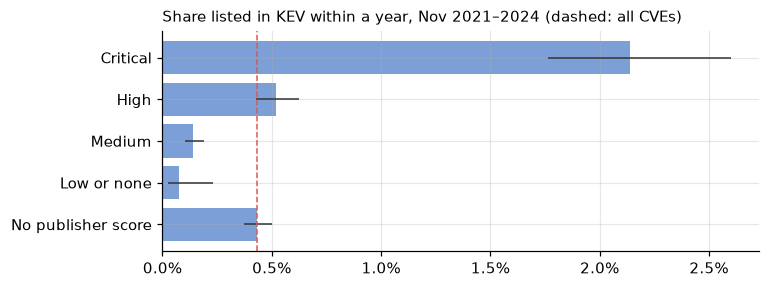

In [18]:
# Check on a textbook case: 0 exploited out of 10 still allows a true rate of up to ~28%
lo, hi = wilson_interval(0, 10)
assert abs(lo) < 1e-12 and abs(hi - 0.2775) < 1e-4

fig, ax = plt.subplots(figsize=(7, 2.6))
y = np.arange(len(by_severity))[::-1]
ax.barh(y, by_severity["rate"], color="#7b9fd6")
below = by_severity["rate"] - by_severity["low"]
above = by_severity["high"] - by_severity["rate"]
ax.errorbar(by_severity["rate"], y, xerr=[below, above], fmt="none", ecolor="#333", elinewidth=1)
ax.axvline(study["label_365"].mean(), color="#e0574f", linestyle="--", linewidth=1)
ax.set_yticks(y, by_severity.index)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1%}"))
ax.set_title("Share listed in KEV within a year, Nov 2021–2024 (dashed: all CVEs)",
             loc="left", fontsize=10)
plt.show()

Critical CVEs are exploited about 5 times as often as the average one, yet they are only about a quarter of the
exploited CVEs. And **41% of CVEs have no publisher score at all**, exploited at the average rate: a severity rule
can't see them.

What does stand out is *who* published the CVE. The NVD identifies publishers by an email address or an ID; its list
of sources (saved by the full download) maps those to names.

In [19]:
sources = json.loads((DATA / "raw" / "nvd_sources.json").read_text(encoding="utf-8"))
PUBLISHER_NAMES = {identifier: s["name"].strip() for s in sources if s.get("name")
                   for identifier in s.get("sourceIdentifiers", [])}


def publisher_of(df):
    "The publisher's name where known, otherwise its identifier."
    return df["cna"].map(PUBLISHER_NAMES).fillna(df["cna"])


study["publisher"] = publisher_of(study)
by_publisher = (study.groupby("publisher")["label_365"].agg(cves="size", exploited="sum")
                     .sort_values("exploited", ascending=False))
top5 = by_publisher.head(5).copy()
top5["rate"] = top5["exploited"] / top5["cves"]
top5["low"], top5["high"] = wilson_interval(top5["exploited"], top5["cves"])

print(f"these 5 publishers: {top5['cves'].sum() / len(study):.0%} of all CVEs, "
      f"{top5['exploited'].sum() / study['label_365'].sum():.0%} of the exploited ones")
pd.DataFrame({"CVEs": top5["cves"].map("{:,}".format), "exploited": top5["exploited"],
              "rate (95% interval)": with_interval(*top5[["rate", "low", "high"]].T.values, 1)})

these 5 publishers: 28% of all CVEs, 53% of the exploited ones


,CVEs,exploited,rate (95% interval)
publisher,,,
Microsoft Corporation,"3,148",86,2.7% (2.2–3.4%)
MITRE,"20,891",60,0.3% (0.2–0.4%)
Apple Inc.,"1,445",35,2.4% (1.7–3.3%)
Chrome,959,28,2.9% (2.0–4.2%)
"Cisco Systems, Inc.",961,15,1.6% (0.9–2.6%)


Even the publisher with the most CVEs overall (MITRE, which assigns IDs for many small vendors) sits below the
average rate, while Microsoft, Apple and Chrome are 5–7 times above it, and their intervals stay well clear of the
average.

**Q3: how fast are exploited CVEs listed?** For every exploited CVE, the days from publication to its KEV listing
(negative means it was listed before the CVE record was even published). Shares get a Wilson interval as before. A
median has no simple formula for its interval, so it gets a **bootstrap** one: the year's CVEs are resampled with
replacement 1,000 times, all at once as one NumPy array, and the middle 95% of the 1,000 medians is the interval.

In [20]:
def bootstrap_median(values, n_boot=1000, seed=510):
    "95% percentile bootstrap interval for the median of `values`."
    values = np.asarray(values, dtype=float)
    rng = np.random.default_rng(seed)
    samples = rng.choice(values, size=(n_boot, values.size), replace=True)   # one row per replay
    return tuple(np.percentile(np.median(samples, axis=1), [2.5, 97.5]))


def timing_summary(days):
    "Listing delays (calendar days) for one year's exploited CVEs."
    d = days.to_numpy(dtype=float)
    on_before, within_30 = int((d <= 0).sum()), int((d <= 30).sum())
    on_low, on_high = wilson_interval(on_before, d.size)
    w30_low, w30_high = wilson_interval(within_30, d.size)
    med_low, med_high = bootstrap_median(d)
    return {"exploited": d.size,
            "on_or_before": on_before / d.size, "on_low": on_low, "on_high": on_high,
            "within_30": within_30 / d.size, "w30_low": w30_low, "w30_high": w30_high,
            "median": np.median(d), "median_low": med_low, "median_high": med_high}


hit = study[study["label_365"]]
by_year = hit.groupby(hit["published"].dt.year)["days_to_kev"]
timing = pd.DataFrame({year: timing_summary(days) for year, days in by_year}).T
timing.index.name = "year"


def share(cols):
    "One share column of `timing` with its interval, as text."
    return with_interval(*timing[cols].T.values, digits=0)


pd.DataFrame({
    "exploited": timing["exploited"].astype(int),
    "listed on or before publication": share(["on_or_before", "on_low", "on_high"]),
    "listed within 30 days": share(["within_30", "w30_low", "w30_high"]),
    "median days": [f"{m:g} ({lo:g}–{hi:g})" for m, lo, hi
                    in timing[["median", "median_low", "median_high"]].to_numpy()],
})

,exploited,listed on or before publication,listed within 30 days,median days
year,,,,
2021,16,31% (14–56%),50% (28–72%),20 (0–140)
2022,112,35% (27–44%),61% (51–69%),14 (3.5–25)
2023,145,32% (25–40%),74% (66–80%),4 (2–7)
2024,149,27% (20–34%),64% (56–71%),7 (3–19)


About **a third of exploited CVEs were in KEV on or before the day they were published** (27–35% in each full year,
with overlapping intervals). The median delay from publication to listing was 4 to 14 days
depending on the year, with wide intervals. For that first third, any ranking made on publication day is already
late; what a ranking can do is put the others near the top straight away. The 2021 row covers only November and
December, so its 16 CVEs give very wide intervals.

## 6. Ranking new CVEs (Q2)

**Which CVEs the model learns from, and which it is tested on.** The CVEs are split by publication date, never at
random, so the model is always tested on CVEs published after everything it learned from, the way it would be used
in practice. CVEs from before KEV started (November 3, 2021) are left out, because their label could not be measured
fairly. Nov 2021–2022 is the **training** window and 2023 the **validation** window: a year kept apart to check the
approach on CVEs the model had not learned from. The final model is then fitted on both together and scores the
2024 **test** year once.

![time windows](figures/split_windows.png)

**How a ranking is scored.** A team works down the list from the top and stops after a fixed share of it, the
**effort** (5%, 10% and 26% here; 26% is what the CVSS 7.0+ rule cost over Nov 2021–2024). **Coverage** is the share of the exploited
CVEs it reached; **precision** is the share of handled CVEs that were exploited. When several CVEs have exactly the
same score and the cut falls among them, nobody can say which one the team would pick, so each counts as partly
handled. The picture shows it on 10 made-up CVEs:

![coverage](figures/coverage_explained.png)

In code this is two pieces. A `Ranking` does the expensive part once per model: it sorts the CVEs and numbers the
groups of equal scores. `coverage` then works from the ranking with running totals and one lookup for where the cut
falls. Splitting it this way pays off later, when the same rankings are measured on 1,000 resampled versions of 2024.

In [21]:
class Ranking:
    "CVEs sorted by score, highest first, with equal scores grouped. Computed once, reused."
    def __init__(self, score):
        score = np.asarray(score, dtype=float)
        if score.size == 0 or not np.isfinite(score).all():
            raise ValueError("scores must be finite and not empty")
        self.order = np.argsort(-score, kind="stable")                       # highest first
        ranked = score[self.order]
        self.group = np.cumsum(np.r_[True, ranked[1:] != ranked[:-1]]) - 1   # tie-group number
        self.n_groups, self.n = int(self.group[-1]) + 1, score.size


def coverage(ranking, y, efforts, weights=None):
    "Expected (coverage, precision) when the top `effort` share is handled; ties split evenly."
    y = np.asarray(y, dtype=float)[ranking.order]
    w = np.ones(ranking.n) if weights is None else np.asarray(weights, dtype=float)[ranking.order]
    size = np.bincount(ranking.group, weights=w, minlength=ranking.n_groups)      # CVEs per group
    hits = np.bincount(ranking.group, weights=w * y, minlength=ranking.n_groups)  # exploited
    cum_size, cum_hits = np.cumsum(size), np.cumsum(hits)
    k = np.asarray(efforts, dtype=float) * cum_size[-1]                 # CVEs handled
    g = np.minimum(np.searchsorted(cum_size, k), ranking.n_groups - 1)  # group holding the cut
    taken = np.divide(k - (cum_size[g] - size[g]), size[g],
                      out=np.zeros_like(k), where=size[g] > 0)          # share of it handled
    found = cum_hits[g] - hits[g] + hits[g] * np.clip(taken, 0, 1)
    total = cum_hits[-1]
    cov = found / total if total > 0 else np.full_like(k, np.nan)
    return cov, np.divide(found, k, out=np.full_like(k, np.nan), where=k > 0)


# The 10 CVEs of the picture: A to J, three exploited (A, D, G); C, D, E and F share 0.6
toy_score = np.array([0.9, 0.8, 0.6, 0.6, 0.6, 0.6, 0.3, 0.2, 0.1, 0.1])
toy_y = np.array([1, 0, 0, 1, 0, 0, 1, 0, 0, 0])
toy = Ranking(toy_score)
print(f"{toy.n} CVEs in {toy.n_groups} tie groups:", toy.group)
cov, prec = coverage(toy, toy_y, [0.1, 0.3, 0.6, 0.7])
for effort, c, p in zip([0.1, 0.3, 0.6, 0.7], cov, prec):
    print(f"handle {effort:.0%}: {c * 3:.2f} of 3 exploited reached, "
          f"coverage {c:.1%}, precision {p:.1%}")

10 CVEs in 6 tie groups: [0 1 2 2 2 2 3 4 5 5]
handle 10%: 1.00 of 3 exploited reached, coverage 33.3%, precision 100.0%
handle 30%: 1.25 of 3 exploited reached, coverage 41.7%, precision 41.7%
handle 60%: 2.00 of 3 exploited reached, coverage 66.7%, precision 33.3%
handle 70%: 3.00 of 3 exploited reached, coverage 100.0%, precision 42.9%


In [22]:
# Checks: the picture's number; a perfect ranking; all-equal scores reach exactly the effort;
# a CVE with weight 2 counts the same as two copies of it
assert np.isclose(coverage(toy, toy_y, [0.3])[0][0], 1.25 / 3)
assert coverage(Ranking(toy_y), toy_y, [0.3])[0][0] == 1.0
assert np.allclose(coverage(Ranking(np.zeros(10)), toy_y, [0.1, 0.5])[0], [0.1, 0.5])
w = np.r_[2, np.ones(9)]
copies = coverage(Ranking(np.r_[toy_score[0], toy_score]), np.r_[toy_y[0], toy_y], [0.3])[0]
assert np.isclose(coverage(toy, toy_y, [0.3], weights=w)[0], copies)
print("ok")

ok


**The model.** Each CVE becomes a row of numbers:

- **structured fields:** publisher, weakness type, CVSS version and each part of the CVSS vector (one 0/1 column per
  value), plus two numbers, the score and the description's length;
- **the words of the cleaned description**, as TF-IDF: one column per word or word pair, larger when the word is in
  this description and rare elsewhere.

A **logistic regression** learns one weight per column and adds them up into a score. Because exploited CVEs are
only about 0.5% of the fitting data, it gives them as much total weight as all the others
(`class_weight="balanced"`), so it can't do well by simply predicting "not exploited". Its one setting, `C`,
controls how strongly the weights are held towards zero, so that no single rare word or publisher dominates.
Both the model and its setting were chosen in a competition, below.

**How this model was chosen.** Logistic regression was not the only option. A competition was held on the
validation year, with its rules fixed in advance:

- **Two model families:** logistic regression (one weight per column, added up) and gradient boosting (hundreds of
  small decision trees, each correcting the ones before; for it the words are first summarised into 100 dense columns).
- **Three sets of columns** for each: the structured fields only, the words only, and both. That makes six candidates.
- **Several settings** for each candidate: logistic regression with five values of `C` (0.01 to 1); gradient
  boosting with eight combinations of the number of trees (100 or 300), the leaves per tree (7 or 15) and the
  smallest leaf (20 or 80 CVEs). That makes **39 fits** in all.
- **The test:** every fit learns from Nov 2021–2022 and ranks the 2023 CVEs. Within each candidate the setting with
  the highest coverage at 10% effort is kept (the first one listed, in a tie); the candidate with the highest
  coverage wins, and the choice is frozen before 2024 is ever scored.

Refitting all 39 takes several minutes (gradient boosting is slow), so the results are read from the saved output of
the full modelling run.

In [23]:
RESULTS = ROOT / "results"
grid = pd.read_csv(RESULTS / "q2_validation_grid.csv")                 # one row per fit: 39 rows
choice = json.loads((RESULTS / "q2_selection.json").read_text(encoding="utf-8"))
chosen = choice["final_model"]

grid["model"] = grid["family"].map({"logistic regression": "LR", "gradient boosting": "GBM"}) + " · " + grid["feature_set"]
SHORT = {"C": "C", "max_iter": "trees", "max_leaf_nodes": "leaves", "min_samples_leaf": "smallest leaf"}
grid["settings"] = grid["settings"].map(lambda s: ", ".join(f"{SHORT[k]} {v}" for k, v in json.loads(s).items()))
best = (grid.sort_values(["model", "coverage_10", "config"], ascending=[True, False, True])
            .groupby("model").head(1).set_index("model"))               # the rule: best at 10%, first in a tie
order = best["coverage_10"].sort_values(ascending=False).index          # candidates, best first

print(f"{len(grid)} fits: {grid['model'].nunique()} candidates, each with its own settings, "
      f"learned on Nov 2021–2022, scored on 2023")
print(f"winner: {order[0]} with {best.loc[order[0], 'settings']} | frozen choice: {chosen}")
pd.DataFrame({
    "settings tried": grid.groupby("model").size()[order],
    "coverage at 10%, worst to best setting": [f"{grid.loc[grid['model'] == m, 'coverage_10'].min():.1%} – "
                                               f"{best.loc[m, 'coverage_10']:.1%}" for m in order],
    "best setting": best.loc[order, "settings"],
    "best setting at 5% / 26%": [f"{best.loc[m, 'coverage_5']:.1%} / {best.loc[m, 'coverage_26']:.1%}" for m in order],
}, index=pd.Index(order, name="candidate"))

39 fits: 6 candidates, each with its own settings, learned on Nov 2021–2022, scored on 2023
winner: LR · structured + text with C 0.1 | frozen choice: LR · structured + text


,settings tried,"coverage at 10%, worst to best setting",best setting,best setting at 5% / 26%
candidate,,,,
LR · structured + text,5,59.3% – 62.1%,C 0.1,49.0% / 75.2%
LR · text,5,53.1% – 60.7%,C 1.0,43.4% / 84.8%
LR · structured,5,44.8% – 56.6%,C 0.01,37.2% / 73.1%
GBM · structured + text,8,47.6% – 54.5%,"trees 300, leaves 7, smallest leaf 20",37.9% / 75.2%
GBM · text,8,46.2% – 51.7%,"trees 300, leaves 15, smallest leaf 20",35.9% / 70.3%
GBM · structured,8,36.6% – 48.3%,"trees 100, leaves 7, smallest leaf 20",37.9% / 68.9%


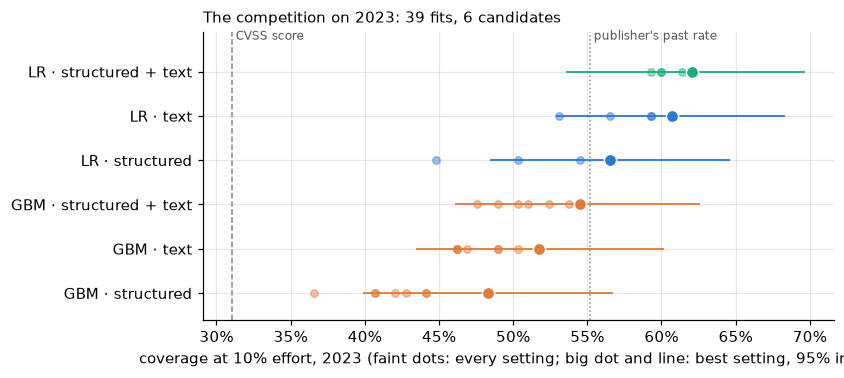

In [24]:
val = pd.read_csv(RESULTS / "q2_validation_models.csv", index_col="model")   # 2023, with 95% intervals
rows = list(order)[::-1]                                                 # the winner on top
fig, ax = plt.subplots(figsize=(7.4, 3.4))
for y, m in enumerate(rows):
    colour = "#1baf7a" if m == chosen else ("#2a78d6" if m.startswith("LR") else "#e07b39")
    tried = grid.loc[grid["model"] == m, "coverage_10"]
    ax.scatter(tried, np.full(len(tried), y), s=24, color=colour, alpha=0.45, zorder=3)
    ax.errorbar(val.loc[m, "coverage_10"], y, xerr=[[val.loc[m, "coverage_10"] - val.loc[m, "coverage_10_low"]],
                [val.loc[m, "coverage_10_high"] - val.loc[m, "coverage_10"]]], fmt="o", color=colour,
                markersize=8, markeredgecolor="white", elinewidth=1.2, capsize=0, zorder=4)
for name, label, style in [("Publisher's past rate", "publisher's past rate", ":"),
                           ("CVSS score, unscored slotted in", "CVSS score", "--")]:
    ax.axvline(val.loc[name, "coverage_10"], color="#888", linestyle=style, linewidth=1)
    ax.text(val.loc[name, "coverage_10"], len(rows) - 0.35, " " + label, fontsize=8, color="#555", va="bottom")
ax.set_yticks(range(len(rows)), rows)
ax.set_ylim(-0.6, len(rows) - 0.1)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("coverage at 10% effort, 2023 (faint dots: every setting; big dot and line: best setting, 95% interval)")
ax.set_title("The competition on 2023: 39 fits, 6 candidates", loc="left", fontsize=10)
plt.show()

In [25]:
diffs = pd.read_csv(RESULTS / "q2_validation_differences.csv")        # paired bootstrap on 2023
d10 = diffs[np.isclose(diffs["effort"], 0.10)]
print(f"{chosen} minus each rival, 2023, 10% effort, points (95% interval):")
for r in d10.itertuples():
    print(f"  {r.compared_with:<33} {100 * r.change:+5.1f} ({100 * r.low:+.1f} to {100 * r.high:+.1f})  "
          f"{'clear' if r.clear else 'not clear'}")

cands = list(order)
pd.DataFrame({"coverage at 10% (95% interval)": with_interval(*val.loc[cands, ["coverage_10", "coverage_10_low",
                                                                                "coverage_10_high"]].T.values, 1),
              "precision at 10%": val.loc[cands, "precision_10"].map("{:.1%}".format)},
             index=pd.Index(cands, name="best setting of each candidate, 2023"))

LR · structured + text minus each rival, 2023, 10% effort, points (95% interval):
  CVSS score, unscored slotted in   +31.0 (+20.4 to +41.7)  clear
  Publisher's past rate              +6.9 (-1.7 to +14.7)  not clear
  LR · structured                    +5.5 (+0.7 to +10.4)  clear


,coverage at 10% (95% interval),precision at 10%
"best setting of each candidate, 2023",,
LR · structured + text,62.1% (53.5–69.7%),3.1%
LR · text,60.7% (52.9–68.3%),3.1%
LR · structured,56.6% (48.4–64.6%),2.8%
GBM · structured + text,54.5% (46.1–62.6%),2.7%
GBM · text,51.7% (43.4–60.1%),2.6%
GBM · structured,48.3% (39.9–56.7%),2.4%


**Why logistic regression on the structured fields plus the words.**

- **It came first.** Its best setting (`C = 0.1`) reached 62.1% of 2023's exploited CVEs at 10% effort, the highest of
  all 39 fits, and it was also the best at 5% effort.
- **The words add clearly.** The same model on the structured fields alone reached 56.6%: the words added +5.5
  points (+0.7 to +10.4), a clear gain even on one year.
- **The flexible model did worse.** Gradient boosting stayed below logistic regression on every set of columns (at
  best 54.5%). With only 128 exploited CVEs in Nov 2021–2022 to learn from, many small trees have little to work with,
  while one weight per column is a sturdier fit.
- **Its reasons can be read.** Every column has one weight (shown further down), so a score can be explained.

Two honest caveats. On 2023 its lead over the publisher's past rate was not yet clear (+6.9 points, −1.7 to +14.7);
on 2024 it was (+12.0, below). And at 26% effort the words-only model did better on 2023; the choice was made at 10%
effort, as fixed in advance.

**Turning a CVE into columns.** Two encoders, each fitted on the past only and then applied unchanged to 2024. The
structured encoder gives a category its own column only if it appears at least 20 times in the fitting data; rarer
or unseen publishers and weakness types share an "other" column. The CVSS vector string (for example
`AV:N/AC:L/PR:N/...`) is split into its parts first. The output at the bottom shows CVE-2024-3400's structured inputs.

In [26]:
MIN_CATEGORY = 20         # CVEs a category needs in the fitting data to get its own column
MAX_CATEGORIES = 250      # at most this many categories per field
TFIDF = {"ngram_range": (1, 2), "min_df": 5, "max_df": 0.5, "max_features": 50_000,
         "sublinear_tf": True, "stop_words": "english"}

COMPONENTS = ["AV", "AC", "PR", "UI", "S", "AT", "C", "I", "A"]
V4_NAMES = {"VC": "C", "VI": "I", "VA": "A"}       # version 4's names for the impact metrics
CATEGORICAL = ["publisher", "cwe", "cvss_version"] + COMPONENTS
NUMERIC = ["cvss_score", "log_description_len"]


def vector_components(vectors):
    "One column per CVSS 3.x/4.0 base component (codes such as N, L, H); 'missing' where absent."
    modern = vectors.where(vectors.str.startswith("CVSS:3", na=False)
                           | vectors.str.startswith("CVSS:4", na=False))
    pairs = modern.str.findall(r"/([A-Z]+):([A-Z])")
    rows = [{V4_NAMES.get(k, k): v for k, v in p} if isinstance(p, list) else {} for p in pairs]
    parsed = pd.DataFrame(rows, index=vectors.index).reindex(columns=COMPONENTS)
    parsed["UI"] = parsed["UI"].replace({"P": "R", "A": "R"})   # passive or active: required
    return parsed.fillna("missing")


def structured_inputs(df):
    "The structured inputs of each CVE, as readable columns (categories as text, two numbers)."
    raw = pd.DataFrame({"publisher": publisher_of(df),
                        "cwe": df["cwe_primary"].fillna("missing"),
                        "cvss_version": df["cvss_version"].fillna("missing").astype(str)},
                       index=df.index)
    raw = raw.join(vector_components(df["cvss_vector"]))
    raw["cvss_score"] = df["cvss_score"].astype(float).fillna(0.0)
    raw["log_description_len"] = np.log1p(df["text"].str.len().astype(float))
    return raw


class StructuredEncoder:
    "Keeps the categories common in the fitting data (the rest become 'other')."
    def fit(self, raw):
        self.keep = {}
        for col in CATEGORICAL:
            counts = raw[col].value_counts()
            common = counts[counts >= MIN_CATEGORY].index[:MAX_CATEGORIES - 1]
            self.keep[col] = sorted(set(common) | {"other"})
        lumped = self.lump(raw)
        self.onehot = OneHotEncoder(categories=[self.keep[c] for c in CATEGORICAL],
                                    handle_unknown="ignore", sparse_output=True)
        self.onehot.fit(lumped[CATEGORICAL])
        self.scaler = StandardScaler().fit(raw[NUMERIC])
        return self

    def lump(self, raw):
        "Categories not kept at fitting time (rare, or never seen) become 'other'."
        out = raw.copy()
        for col in CATEGORICAL:
            out[col] = out[col].where(out[col].isin(self.keep[col]), "other")
        return out

    def sparse(self, raw):
        "0/1 columns for each kept category, plus the standardised numbers."
        lumped = self.lump(raw)
        return sp.hstack([self.onehot.transform(lumped[CATEGORICAL]),
                          sp.csr_matrix(self.scaler.transform(raw[NUMERIC]))]).tocsr()

    def names(self):
        return [f"{col}: {cat}" for col in CATEGORICAL for cat in self.keep[col]] + NUMERIC


class TextEncoder:
    "TF-IDF of the cleaned descriptions, with the vocabulary learned from the fitting data."
    def fit(self, texts):
        self.tfidf = TfidfVectorizer(dtype=np.float32, **TFIDF).fit(texts)
        return self

    def sparse(self, texts):
        return self.tfidf.transform(texts)

    def names(self):
        return [f"word: {w}" for w in self.tfidf.get_feature_names_out()]


structured_inputs(study[study["cve_id"] == "CVE-2024-3400"].set_index("cve_id"))

,publisher,cwe,cvss_version,AV,AC,PR,UI,S,AT,C,I,A,cvss_score,log_description_len
cve_id,,,,,,,,,,,,,,
CVE-2024-3400,"Palo Alto Networks, Inc.",CWE-20,3.1,N,L,N,N,C,missing,H,H,H,10.0,5.991465


**Fitting and scoring.** The winner, with its chosen setting, is refitted on Nov 2021–2023 (the training and
validation years together) and then scores every 2024 CVE, once.

In [27]:
C = choice["candidates"][chosen]["params"]["C"]   # the setting chosen on 2023 (smaller = stronger hold)
fit = study[study["split"].isin(["train", "validate"])].reset_index(drop=True)
test = study[study["split"] == "test"].reset_index(drop=True)

structured = StructuredEncoder().fit(structured_inputs(fit))
words = TextEncoder().fit(fit["text"])


def features(df):
    "Structured columns and word columns side by side, as one sparse matrix."
    parts = [structured.sparse(structured_inputs(df)), words.sparse(df["text"])]
    return sp.hstack(parts).tocsr()


X_fit, X_test = features(fit), features(test)
model = LogisticRegression(C=C, class_weight="balanced", solver="liblinear", max_iter=2000)
model.fit(X_fit, fit["label_365"])
test["model"] = model.predict_proba(X_test)[:, 1]
print(f"learned from {X_fit.shape[0]:,} CVEs ({int(fit['label_365'].sum())} exploited)")
print(f"columns: {len(structured.names())} structured + {len(words.names()):,} words "
      f"= {X_fit.shape[1]:,}")

learned from 57,184 CVEs (273 exploited)
columns: 327 structured + 44,570 words = 44,897


Two simple rankings to beat, both learned from Nov 2021–2023 only:

- **CVSS score:** the publisher's severity score. CVEs without one are slotted in at 8.0, inside "High", the band
  whose past exploitation rate is closest to theirs.
- **Publisher's past rate:** each publisher's exploitation rate, pulled towards the overall rate by 50 imaginary
  average CVEs so a small publisher isn't ranked on two or three cases.

In [28]:
test["cvss"] = test["cvss_score"].fillna(8.0)

overall = fit["label_365"].mean()
counts = fit.groupby("publisher")["label_365"].agg(["sum", "size"])
past_rate = (counts["sum"] + 50 * overall) / (counts["size"] + 50)
# a publisher never seen before gets the overall rate
test["publisher_rate"] = test["publisher"].map(past_rate).fillna(overall)

EFFORTS = [0.05, 0.10, 0.26]
y_test = test["label_365"].to_numpy()
rankings = {"model": "model", "CVSS score": "cvss", "publisher's past rate": "publisher_rate"}
ranked = {name: Ranking(test[col]) for name, col in rankings.items()}   # sorted once each
print(f"{len(ranked)} rankings of the {len(test):,} CVEs of 2024 ({int(y_test.sum())} exploited)")

3 rankings of the 39,953 CVEs of 2024 (149 exploited)


**Results, and is the gap real or luck?** The table below gives each ranking's coverage at 5%, 10% and 26% effort,
and its precision at 10% effort: the share of the CVEs in its top 10% that were exploited. For comparison, a list in
random order reaches on average exactly its effort in coverage (5%, 10% and 26%), and its precision is simply the
share of 2024's CVEs that were exploited, 0.37%.

2024 has only 149 exploited CVEs, so the year is replayed 1,000 times: each replay draws 39,953 CVEs at random
*with replacement* (some twice, some not at all), and every ranking is measured on the same replays. A replay is just
a weight per CVE (how many times it was drawn), so the rankings sorted above are reused as they are. The middle 95%
of each ranking's 1,000 results is its interval (for coverage and for precision), and the middle 95% of the
paired differences is the interval for the coverage gap, shown at 10% effort, the main effort. If that interval doesn't include zero, the difference is clear. The
same function is reused for every comparison below.

In [29]:
def replay_coverage(y, rankings, efforts=(0.10,), n_boot=1000, seed=510, with_precision=False):
    "Coverage (and precision, if asked) of each ranking on the same n_boot resamples."
    rng, n = np.random.default_rng(seed), len(y)
    cov = np.empty((n_boot, len(rankings), len(efforts)))      # (replays, rankings, efforts)
    prec = np.empty_like(cov)
    for b in range(n_boot):
        w = np.bincount(rng.integers(0, n, n), minlength=n)     # how often each CVE was drawn
        for j, r in enumerate(rankings):
            cov[b, j], prec[b, j] = coverage(r, y, efforts, weights=w)
    return (cov, prec) if with_precision else cov


def points(diff, low, high):
    "A difference in coverage and its 95% interval, in percentage points."
    return f"{100 * diff:+.1f} ({100 * low:+.1f} to {100 * high:+.1f})"


names = list(ranked)
measured = [coverage(r, y_test, EFFORTS) for r in ranked.values()]   # the year itself
point = np.array([cov for cov, _ in measured])                      # coverage (rankings, efforts)
point_prec = np.array([prec for _, prec in measured])               # precision (rankings, efforts)

replays, replays_prec = replay_coverage(y_test, list(ranked.values()), EFFORTS, with_precision=True)
low, high = np.percentile(replays, [2.5, 97.5], axis=0)
prec_low, prec_high = np.percentile(replays_prec, [2.5, 97.5], axis=0)
gap_low, gap_high = np.percentile(replays[:, [0]] - replays, [2.5, 97.5], axis=0)
i10 = EFFORTS.index(0.10)                                           # the main effort

coverage_cols = {f"coverage {e:.0%}": with_interval(point[:, i], low[:, i], high[:, i], 1)
                 for i, e in enumerate(EFFORTS)}
q2_table = pd.DataFrame(coverage_cols, index=names)
q2_table["precision 10%"] = with_interval(point_prec[:, i10], prec_low[:, i10],
                                             prec_high[:, i10], 1)
q2_table["model minus this, 10%"] = ["–"] + [
    points(point[0, i10] - point[j, i10], gap_low[j, i10], gap_high[j, i10]) for j in (1, 2)]
q2_table

,coverage 5%,coverage 10%,coverage 26%,precision 10%,"model minus this, 10%"
model,57.7% (49.4–66.0%),76.5% (68.8–83.5%),90.6% (85.5–95.0%),2.9% (2.3–3.4%),–
CVSS score,31.7% (24.3–39.4%),36.7% (28.9–44.9%),52.7% (45.8–59.5%),1.4% (1.0–1.8%),+39.8 (+30.8 to +48.0)
publisher's past rate,32.7% (26.2–40.0%),64.5% (56.8–71.9%),75.8% (68.7–82.4%),2.4% (1.9–2.9%),+12.0 (+3.1 to +20.7)


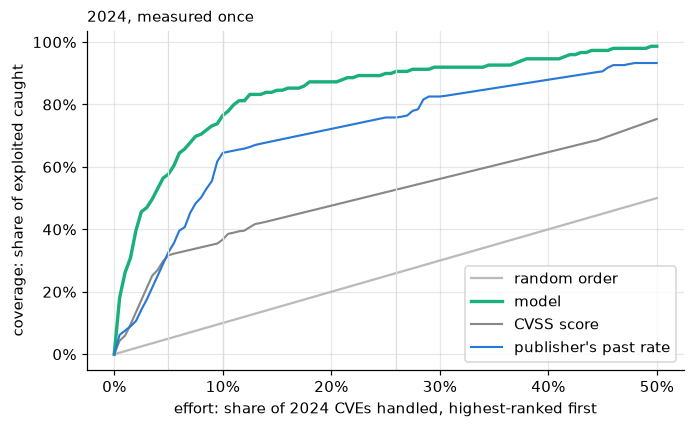

In [30]:
grid = np.linspace(0, 0.5, 101)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot([0, 0.5], [0, 0.5], color="#bbb", label="random order")
for (name, r), colour in zip(ranked.items(), ["#1baf7a", "#888", "#2a78d6"]):
    width = 2.2 if name == "model" else 1.4
    ax.plot(grid, coverage(r, y_test, grid)[0], color=colour, linewidth=width, label=name)
for e in EFFORTS:
    ax.axvline(e, color="#ddd", linewidth=0.8)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("effort: share of 2024 CVEs handled, highest-ranked first")
ax.set_ylabel("coverage: share of exploited caught")
ax.set_title("2024, measured once", loc="left", fontsize=10)
ax.legend(loc="lower right")
plt.show()

Handling the top 10% of 2024's CVEs, the model reaches **76.5%** of the exploited ones (95% interval 68.8–83.5%),
against 36.7% for the CVSS score and 64.5% for the publisher's history. Both gaps are clear: +39.8 points (+30.8 to
+48.0) and +12.0 points (+3.1 to +20.7).

**What do the description's words add?** The same model without the word columns: structured fields only. With far
fewer columns it uses a stronger hold on its weights (`C = 0.01`, its own best setting on 2023).

In [31]:
C_fields = choice["candidates"]["LR · structured"]["params"]["C"]   # its best setting on 2023
fields_only = LogisticRegression(C=C_fields, class_weight="balanced", solver="liblinear",
                                 max_iter=2000)
fields_only.fit(structured.sparse(structured_inputs(fit)), fit["label_365"])
test["fields_only"] = fields_only.predict_proba(structured.sparse(structured_inputs(test)))[:, 1]

fields_ranking = Ranking(test["fields_only"])
fields_cov = coverage(fields_ranking, y_test, [0.10])[0][0]
pair = replay_coverage(y_test, [ranked["model"], fields_ranking])[:, :, 0]   # same replays
words_low, words_high = np.percentile(pair[:, 0] - pair[:, 1], [2.5, 97.5])
model_cov = point[0, i10]                                                     # from the table above
print(f"coverage at 10% effort, 2024: structured fields only {fields_cov:.1%}, "
      f"with the words {model_cov:.1%}")
print("gain from the words, points (95% interval):",
      points(model_cov - fields_cov, words_low, words_high))

coverage at 10% effort, 2024: structured fields only 55.0%, with the words 76.5%
gain from the words, points (95% interval): +21.5 (+14.5 to +27.2)


The words lift coverage from 55.0% to 76.5%, a clear gain. Which columns push a CVE up the list? The largest weights:

In [32]:
names = structured.names() + words.names()
weights = pd.Series(model.coef_[0], index=names).sort_values(ascending=False)
print(weights.head(12).round(2).to_string())

publisher: Atlassian                2.74
publisher: VMware                   2.67
publisher: Google Inc.              2.30
word: strike                        2.29
word: roundcube                     2.24
word: zimbra                        2.18
publisher: Microsoft Corporation    2.13
word: 2023                          2.06
cwe: CWE-1188                       1.97
word: unauthenticated               1.95
publisher: QNAP Systems, Inc.       1.90
word: service elevation             1.87


## 7. Against EPSS (Q4)

EPSS, run by FIRST, scores every CVE daily with the chance of exploitation activity in the next 30 days, using far
more than this project has (exploit code, scanner traffic, chatter, and KEV itself). The full download collected each
2024 CVE's EPSS score 1, 7 and 30 days after publication. CVEs that EPSS hadn't scored yet go to the bottom of its
list.

The comparison is made twice:

- **All CVEs:** every 2024 CVE, exactly as a team would meet them. The model's list is made on publication day; EPSS's
  list uses its score 1, 7 or 30 days later, so EPSS has had more time to see evidence.
- **Equal information:** EPSS reads KEV itself. If a CVE was already listed in KEV by the day of the EPSS score, EPSS
  is partly reporting a known fact rather than predicting. So, for each EPSS day, the exploited CVEs that KEV had
  already listed by then are dropped from both lists, and the two rankings are compared on the rest. CVEs that
  were never exploited always stay in.

The diagram shows the rule for the day-7 score:

![epss views](figures/epss_views.png)

In [33]:
epss = pd.read_parquet(DATA / "processed" / "epss_benchmark.parquet")
epss["score_day"] = epss["score_day"].fillna(epss["target_day"])
wide = epss.pivot(index="cve_id", columns="horizon_days", values=["epss", "score_day"])
wide.columns = [f"{what}_{h}" for what, h in wide.columns]    # epss_1, score_day_1, ...

q4 = test.join(wide, on="cve_id")
rows = []
for h in (1, 7, 30):
    epss_score = q4[f"epss_{h}"].astype(float).fillna(-1.0)   # not scored yet -> last
    score_day = pd.to_datetime(q4[f"score_day_{h}"])
    already = q4["kev_date_added"].notna() & (q4["kev_date_added"] <= score_day)
    keep = ~(already & q4["label_365"])             # drop exploited CVEs already in KEV
    views = [("all CVEs", np.ones(len(q4), bool)), ("equal information", keep.to_numpy())]
    for view, mask in views:
        yv = q4.loc[mask, "label_365"].to_numpy()
        pair_h = [Ranking(q4.loc[mask, "model"]), Ranking(epss_score[mask])]
        model_h, epss_h = (coverage(r, yv, [0.10])[0][0] for r in pair_h)
        rep = replay_coverage(yv, pair_h)[:, :, 0]
        gap_lo, gap_hi = np.percentile(rep[:, 0] - rep[:, 1], [2.5, 97.5])
        rows.append({"EPSS day": h, "view": view, "exploited": int(yv.sum()),
                     "model": model_h, "EPSS": epss_h, "gap": model_h - epss_h,
                     "low": gap_lo, "high": gap_hi, "clear": gap_lo > 0 or gap_hi < 0})
q4_table = pd.DataFrame(rows).set_index(["view", "EPSS day"]).sort_index()

pd.DataFrame({
    "exploited": q4_table["exploited"],
    "model": q4_table["model"].map("{:.1%}".format),
    "EPSS": q4_table["EPSS"].map("{:.1%}".format),
    "model minus EPSS, points (95% interval)": [points(*r) for r in
                                                q4_table[["gap", "low", "high"]].to_numpy()],
    "clear difference": q4_table["clear"].map({True: "yes", False: "no"}),
})

exploited  model   EPSS model minus EPSS, points (95% interval) clear difference
view              EPSS day                                                                                  
all CVEs          1               149  76.5%  34.6%                  +41.9 (+32.3 to +51.3)              yes
                  7               149  76.5%  56.4%                   +20.1 (+9.1 to +30.6)              yes
                  30              149  76.5%  74.5%                    +2.0 (-7.7 to +11.2)               no
equal information 1                96  74.0%  15.2%                  +58.8 (+49.1 to +68.7)              yes
                  7                71  74.6%  26.8%                  +47.9 (+34.7 to +61.7)              yes
                  30               54  75.9%  46.3%                  +29.6 (+15.7 to +44.1)              yes

**How to read the table.** Each row is one EPSS day (1, 7 or 30 days after publication) in one of the two views.
`exploited` is the number of exploited CVEs still in the lists; `model` and `EPSS` are the shares of them each
ranking catches in its top 10%. The gap column is model minus EPSS in percentage points, with its 95% interval, and
"clear difference" says whether that interval excludes zero.

**All CVEs.** The model's publication-day list (76.5%) is clearly ahead of EPSS one day later (34.6%) and a week
later (56.4%). EPSS improves as evidence arrives, and a month later it reaches 74.5%: the gap of 2 points is not a
clear difference, so the two are level.

**Equal information.** In 2024, KEV had already listed 53 of the 149 exploited CVEs by the day of the EPSS day-1
score, 78 by day 7 and 95 by day 30 (149 minus the `exploited` column). Once those are dropped, EPSS falls to
15–46%, while the model barely moves (74–76%), because it never looks at KEV. The model is clearly ahead on all
three days. Most of EPSS's late strength therefore comes from CVEs whose exploitation was already public.

**What this means in practice.** On the day a CVE appears, the publication-day ranking gives the better order. EPSS
is free and updated every day, so the two can work together: rank new CVEs by the model on day 0, then let EPSS
reorder them as evidence comes in.

## 8. Conclusion

- **Severity is a weak filter.** In 2024 "fix everything CVSS 7.0+" meant fixing a third of all CVEs and still
  missed 38% of the exploited ones. Over Nov 2021–2024, 41% of CVEs had no publisher score at all.
- **Who published a CVE says more than its severity.** Over Nov 2021–2024, five publishers account for 28% of
  CVEs but 53% of the exploited ones.
- **Publication-day facts are enough to rank well.** Handling the top 10% of 2024's CVEs, the model reached 76.5% of
  the exploited ones (95% interval 68.8–83.5%), against 36.7% for CVSS and 64.5% for the publisher's history (both
  differences clear).
- **The description's words matter,** once the sentences that give the answer away are removed: they raise 2024
  coverage at 10% effort from 55.0% (structured fields only) to 76.5%, a clear gain.
- **A simple model won a fair competition.** Of 39 settings of logistic regression and gradient boosting tried on
  2023, logistic regression on the structured fields plus the words came first, and was frozen before 2024 was
  scored once.
- **Against EPSS,** the model on publication day clearly beats EPSS one day and one week later, and is level with it
  a month later; on equal information it is clearly ahead on all three days.
- **Some CVEs can't be anticipated:** about a third were in KEV on or before publication day.

**Limitations.** KEV is a conservative label (some exploited CVEs never make it in); the test is one year with 149
exploited CVEs; descriptions are as of November 2026 (cleaned, but possibly edited since publication); and
"publisher" means whoever assigned the CVE, which is not always the vendor.

---

## Try it: the app

The same model runs **NeedlePoint**, a small Streamlit app (*find the needle on day one*): paste any CVE IDs and get them ranked with the reasons behind each score
(newer CVEs are looked up live at the NVD), replay any month of 2024, compare every ranking with EPSS, and explore the
findings above.

Start it from the project folder with `streamlit run app/Home.py` (or double-click `start_app.bat`), then open
**[http://localhost:8501](http://localhost:8501)**.